Rule              Ep50   Ep100   Ep150   Ep200    Test
────────────── ─────── ─────── ─────── ─────── ───────
hebbian         50.9%  50.9%  50.9%  50.9%  53.8%
perceptron      96.2%  96.2%  96.2%  96.2%  96.2%
delta           95.9%  95.9%  95.9%  96.2%  96.2%
correlation     50.9%  50.9%  50.9%  50.9%  53.8%
outstar         95.9%  95.9%  95.9%  95.9%  96.2%

Best rule: perceptron (test acc: 96.2%)


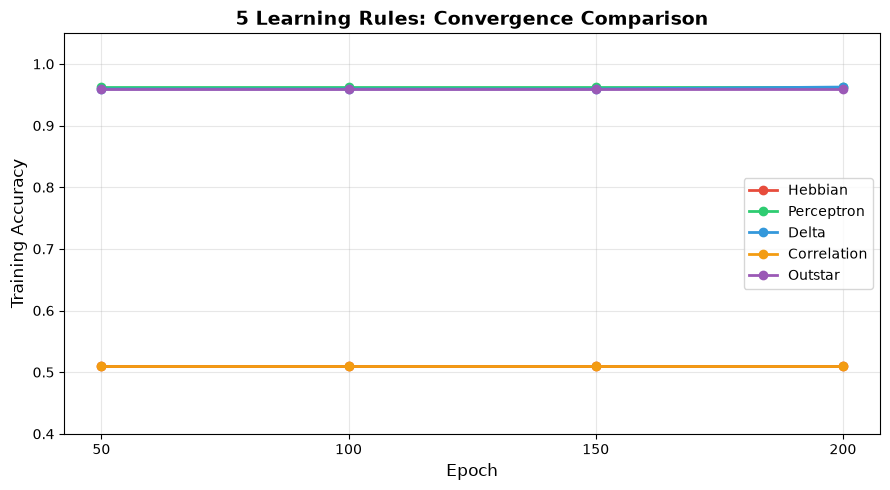

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# --- Generate Data ---
np.random.seed(42)
n = 400

X = np.column_stack([
    np.concatenate([np.random.normal(3, 1.5, 200), np.random.normal(7, 1.8, 200)]),
    np.concatenate([np.random.normal(55, 12, 200), np.random.normal(78, 10, 200)])
]).astype(np.float32)
y = np.concatenate([np.zeros(200), np.ones(200)])

idx = np.random.permutation(n)
X, y = X[idx], y[idx]

mean, std = X.mean(0), X.std(0)
X = (X - mean) / std

split = 320
Xtr, Xte = X[:split], X[split:]
ytr, yte = y[:split], y[split:]

# --- Single Neuron with 5 Learning Rules ---
class Neuron:
    def __init__(self, n=2, lr=0.01):
        self.w = np.random.randn(n).astype(np.float32) * 0.1
        self.b = np.float32(0.0)
        self.lr = lr

    @staticmethod
    def sig(z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def acc(self, X, y):
        pred = (self.sig(X @ self.w + self.b) >= 0.5).astype(int)
        # Hebbian may flip orientation
        alt = (self.sig(X @ self.w + self.b) < 0.5).astype(int)
        return max(np.mean(pred == y.astype(int)),
                   np.mean(alt == y.astype(int)))

    def train(self, X, y, rule, epochs=200):
        log = []
        for e in range(epochs):
            if rule == 'hebbian':
                for xi in X:
                    yo = self.sig(xi @ self.w + self.b)
                    self.w += self.lr * yo * xi
                    self.b += self.lr * yo
                    self.w = np.clip(self.w, -10, 10)
            elif rule == 'perceptron':
                for xi, t in zip(X, y):
                    pred = 1.0 if xi @ self.w + self.b >= 0 else 0.0
                    self.w += self.lr * (t - pred) * xi
                    self.b += self.lr * (t - pred)
            elif rule == 'delta':
                for xi, t in zip(X, y):
                    o = self.sig(xi @ self.w + self.b)
                    g = o * (1 - o)
                    self.w += self.lr * (t - o) * g * xi
                    self.b += self.lr * (t - o) * g
            elif rule == 'correlation':
                for xi, t in zip(X, y):
                    self.w += self.lr * t * xi
                    self.b += self.lr * t
                self.w = np.clip(self.w, -10, 10)
            elif rule == 'outstar':
                for xi, t in zip(X, y):
                    self.w += self.lr * xi * (t - self.w)
                    self.b += self.lr * (t - self.b)
            if (e + 1) % 50 == 0:
                log.append(self.acc(Xtr, ytr))
        return log

# --- Train All Rules ---
rules = ['hebbian', 'perceptron', 'delta', 'correlation', 'outstar']
results = {}

for rule in rules:
    np.random.seed(42)
    n = Neuron(lr=0.01)
    log = n.train(Xtr, ytr, rule)
    results[rule] = {'log': log, 'test': n.acc(Xte, yte),
                     'w': n.w.copy(), 'b': n.b}

# --- Print Results ---
print(f"{'Rule':<14} {'Ep50':>7} {'Ep100':>7} {'Ep150':>7} {'Ep200':>7} {'Test':>7}")
print(f"{'─'*14} {'─'*7} {'─'*7} {'─'*7} {'─'*7} {'─'*7}")
for rule in rules:
    r = results[rule]
    vals = r['log']
    print(f"{rule:<14} {vals[0]:>6.1%} {vals[1]:>6.1%} {vals[2]:>6.1%} {vals[3]:>6.1%} {r['test']:>6.1%}")

best = max(results, key=lambda r: results[r]['test'])
print(f"\nBest rule: {best} (test acc: {results[best]['test']:.1%})")

# --- Convergence Graph ---
colors = ['#e74c3c', '#2ecc71', '#3498db', '#f39c12', '#9b59b6']
fig, ax = plt.subplots(figsize=(9, 5))

for rule, color in zip(rules, colors):
    ax.plot([50, 100, 150, 200], results[rule]['log'],
            marker='o', linewidth=2, color=color, label=rule.capitalize())

ax.set_xlabel('Epoch', fontsize=12)
ax.set_ylabel('Training Accuracy', fontsize=12)
ax.set_title('5 Learning Rules: Convergence Comparison', fontsize=14, fontweight='bold')
ax.set_ylim(0.4, 1.05)
ax.set_xticks([50, 100, 150, 200])
ax.legend(fontsize=10)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()